# Sales Analysis
### The following steps are followed to complete the task 

 #### Step 1: Prepare Data for Analysis

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

In [8]:
# Reading the csv file and storing it as a DataFrame named df
df = pd.read_csv("Sales.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%y") 

The data column in the CSV file stores value like 01-Oct-20, which use day–abbreviated month–two‑digit year format.To correctly parse the dates, I specified the format string "%d-%b-%y" when reading the CSV. Here, %d represents the day, %b the abbreviated month name (e.g., Oct), and %y the two‑digit year (e.g., 20 for 2020). 

In [9]:
# print the DataFrame
df

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500
...,...,...,...,...,...,...
7555,2020-12-30,Afternoon,TX,Seniors,14,35000
7556,2020-12-30,Evening,TX,Kids,15,37500
7557,2020-12-30,Evening,TX,Men,15,37500
7558,2020-12-30,Evening,TX,Women,11,27500


Here we have there is **7560 rows** and **6 columns**.
- **Date** column, beginning with *1-Oct-2020* and ending with 30-Dec-2020.
- **Time** column is showing *Morning*, *Afternoon* and *Evening*.
- **State** is indicating the different states of the United States
- **Group** is categories with *Kids*, *Men*, *Women* and *Seniors*.
- **Unit** and **Sales** contain the numerical data.

In [10]:
# Check the missing values
df.isna().sum()

Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

In [11]:
# Verifying that there are no non-missing values in the DataFrame
df.notna().sum()

Date     7560
Time     7560
State    7560
Group    7560
Unit     7560
Sales    7560
dtype: int64

There is no missing and NA values. This shows the data is clean

#### Step 2: Normalize Data for Analysis

In [12]:
# Creating a new DataFrame called df_dataonly
df_dataonly = df[['Unit', 'Sales']]

In [13]:
# Creating a normalize object 
normalize = MinMaxScaler()

In [14]:
#  Invoking the fit_transform() method, and passing this newly created object called df_dataonly
normalize_data = normalize.fit_transform(df_dataonly)

In [17]:
normalize_data[:, [0]] # list all the values of normailzed Unit values

array([[0.0952381 ],
       [0.0952381 ],
       [0.03174603],
       ...,
       [0.20634921],
       [0.14285714],
       [0.17460317]], shape=(7560, 1))

In [19]:
normalize_data[:, [1]] # list all the values of normalized Sales values

array([[0.0952381 ],
       [0.0952381 ],
       [0.03174603],
       ...,
       [0.20634921],
       [0.14285714],
       [0.17460317]], shape=(7560, 1))

To Check the min and max values of each of the column. Min should be 0.0 and max should be 1.0, for **Unit** as well as **Sales** column

In [20]:
print(normalize_data[:, [0]].min(), normalize_data[:, [0]].max())

0.0 0.9999999999999999


In [21]:
print(normalize_data[:, [1]].min(), normalize_data[:, [1]].max())

0.0 1.0


#### Step 3: Visualize Overall Trends

In [22]:
# Ploting the Date versus Unit and Date versus Sales line plot
dates = df['Date']

df_unit_and_sales = df.groupby(by='Date', axis='index').sum()

C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_4752\1535657103.py:4: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  df_unit_and_sales = df.groupby(by='Date', axis='index').sum()


In [23]:
df_unit_and_sales

,Time,State,Group,Unit,Sales
Date,,,,,
2020-10-01,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1488,3720000
2020-10-02,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1486,3715000
2020-10-03,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1556,3890000
2020-10-04,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1488,3720000
2020-10-05,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1545,3862500
...,...,...,...,...,...
2020-12-26,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1886,4715000
2020-12-27,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1855,4637500
2020-12-28,Morning Morning Morning Morning Afternoon Aft...,WA WA WA WA WA WA WA WA WA WA WA WAAZAZAZAZAZ...,Kids Men Women Seniors Kids Men Women Seniors...,1838,4595000


#### Step 4: Analyze Monthly Data
Here we have chunk this quarterly data into monthly data and perform the analysis. 
For each of the month, get the sub-DataFrame, using the ```loc``` feature of DataFrame, and pass the range by date. 

In [27]:
# For October
df_oct = df_unit_and_sales.loc['2020-10-01':'2020-10-30'] 

In [28]:
# For November
df_nov = df_unit_and_sales.loc['2020-11-01':'2020-11-30']

In [29]:
# For December
df_dec = df_unit_and_sales.loc['2020-12-01':'2020-12-31']

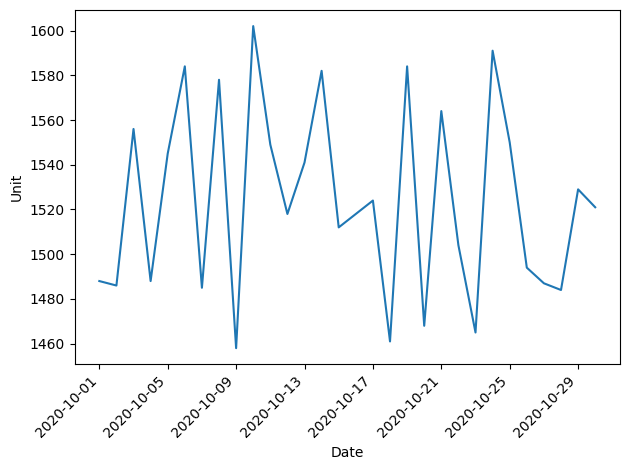

In [39]:
# LIne Chart for month of october 
sns.lineplot(x = df_oct.index, y = 'Unit', data=df_oct)
# to Fix overlapping dates
plt.xticks(rotation=45, ha='right') # Horizontal Alignment ha='right' aligns the date ends with the tick
plt.tight_layout() # Ensures labels aren't cut off at the bottom
plt.show()

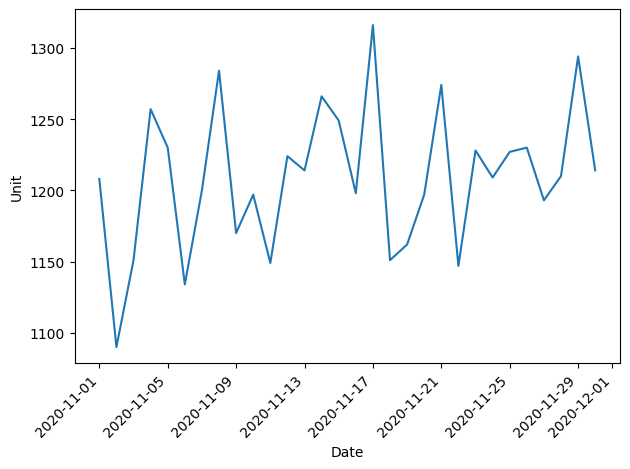

In [37]:
# LIne Chart for month of November
sns.lineplot(x = df_nov.index, y = 'Unit', data=df_nov)
# to Fix overlapping dates
plt.xticks(rotation=45, ha='right') # Horizontal Alignment ha='right' aligns the date ends with the tick
plt.tight_layout() # Ensures labels aren't cut off at the bottom
plt.show()

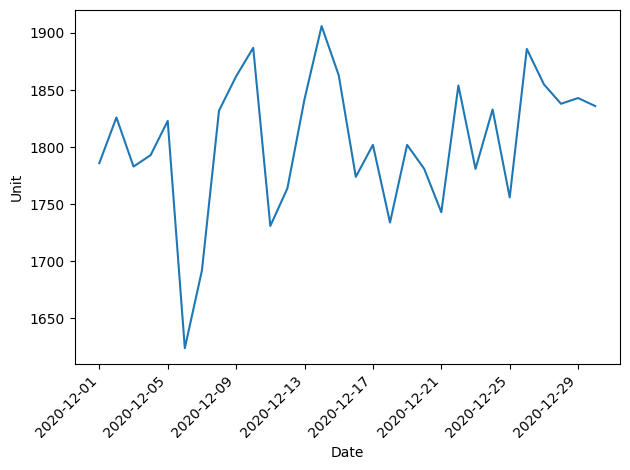

In [40]:
# LIne Chart for month of December 
sns.lineplot(x = df_dec.index, y = 'Unit', data=df_dec)
# to Fix overlapping dates
plt.xticks(rotation=45, ha='right') # Horizontal Alignment ha='right' aligns the date ends with the tick
plt.tight_layout() # Ensures labels aren't cut off at the bottom
plt.show()

#### Step 5: Describe Data
To describing the data to get the basic information such as count, mean, std (standard deviation), min, max and the quartiles. 

In [41]:
# Describing the data 
df.describe()

,Date,Unit,Sales
count,7560,7560.000000,7560.000000
mean,2020-11-15 04:00:00.000000256,18.005423,45013.558201
min,2020-10-01 00:00:00,2.000000,5000.000000
25%,2020-10-23 00:00:00,8.000000,20000.000000
50%,2020-11-15 12:00:00,14.000000,35000.000000
75%,2020-12-08 00:00:00,26.000000,65000.000000
max,2020-12-30 00:00:00,65.000000,162500.000000
std,NaN,12.901403,32253.506944


In [44]:
# For October month
df_oct.describe()

,Unit,Sales
count,30.000000,3.000000e+01
mean,1523.866667,3.809667e+06
std,43.041867,1.076047e+05
min,1458.000000,3.645000e+06
25%,1487.250000,3.718125e+06
50%,1519.500000,3.798750e+06
75%,1554.500000,3.886250e+06
max,1602.000000,4.005000e+06


In [45]:
# For November month
df_nov.describe()

,Unit,Sales
count,30.000000,3.000000e+01
mean,1209.100000,3.022750e+06
std,51.177413,1.279435e+05
min,1090.000000,2.725000e+06
25%,1175.750000,2.939375e+06
50%,1209.500000,3.023750e+06
75%,1230.000000,3.075000e+06
max,1316.000000,3.290000e+06


In [46]:
# For December month
df_dec.describe()

,Unit,Sales
count,30.000000,3.000000e+01
mean,1804.400000,4.511000e+06
std,61.370329,1.534258e+05
min,1624.000000,4.060000e+06
25%,1775.750000,4.439375e+06
50%,1812.500000,4.531250e+06
75%,1842.750000,4.606875e+06
max,1906.000000,4.765000e+06


#### Step 6: Analyze Unit data

 **Unit Analysis**

[Text(0.5, 1.0, 'December Units')]

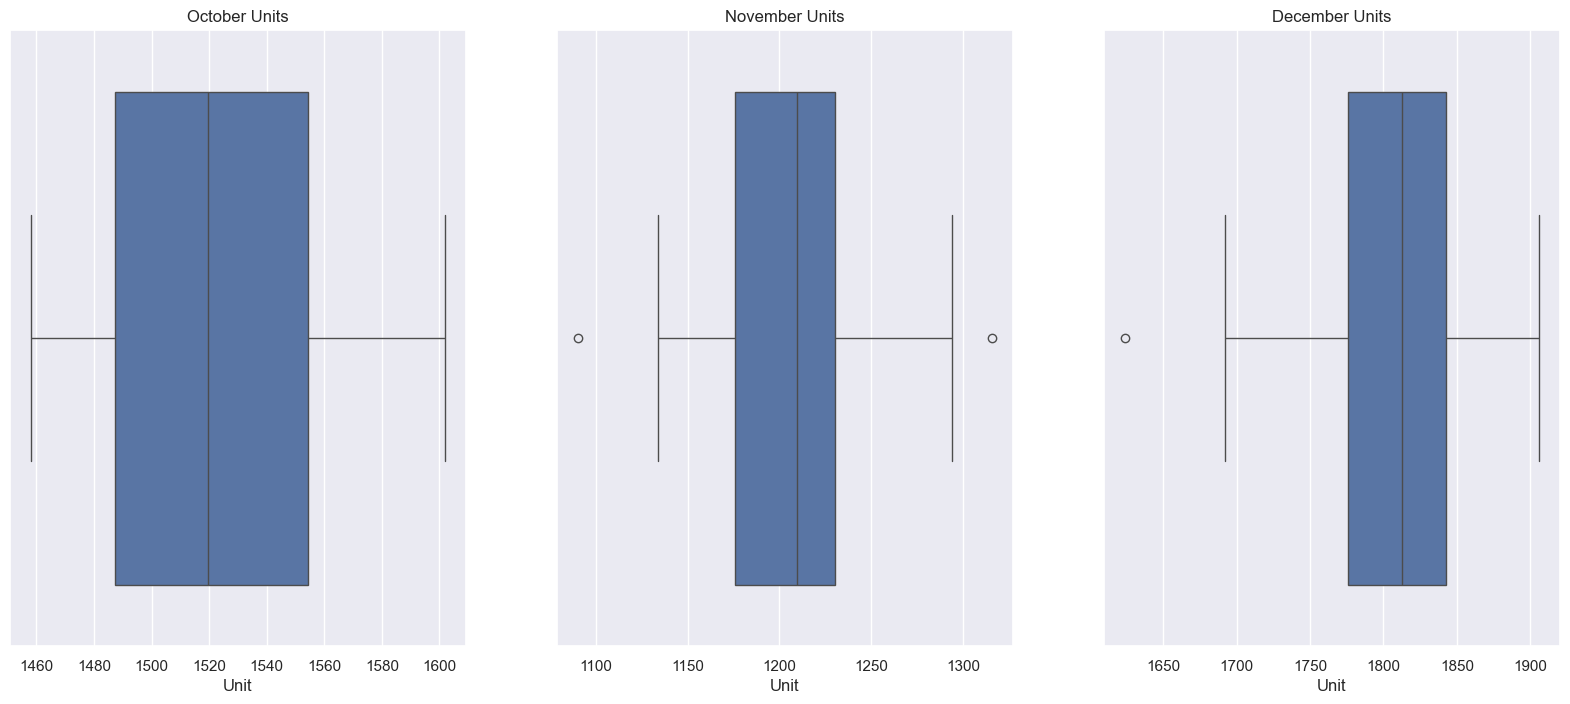

In [47]:
# Configure seaborn aesthetics for plot size
sns.set(rc={'figure.figsize':(20,8)})

# Create a figure and a row of 3 subplots
fig, axes = plt.subplots(1, 3)

# Create boxplots for Units sold in October, November, December
bp_oct = sns.boxplot(x='Unit', data=df_oct, ax=axes[0])
bp_nov = sns.boxplot(x='Unit', data=df_nov, ax=axes[1])
bp_dec = sns.boxplot(x='Unit', data=df_dec, ax=axes[2])

# Set titles for each subplot based on month
bp_oct.set(title='October Units')
bp_nov.set(title='November Units')
bp_dec.set(title='December Units')

Here we can observe in the above boxplots the variation in the quartiles for three different months. 
- Month of October shows a rather wide-spread with a mean value of 1523.
- Month of November and December, they are rather narrow.
- For November, the mean value is 1209, and for the month of December, it is 1804. 

**Sales Analysis**

[Text(0.5, 1.0, 'December Sales')]

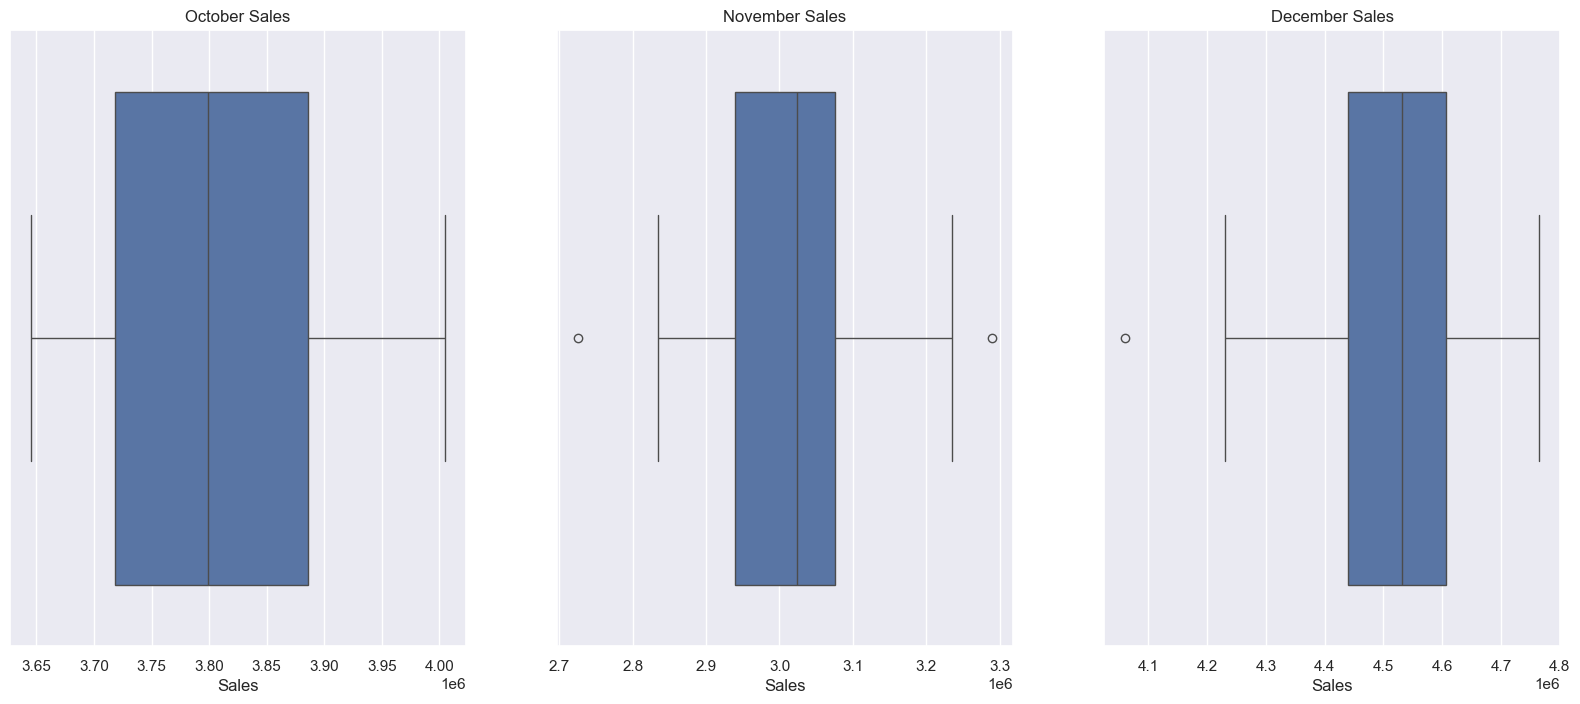

In [48]:
# Create box plots comparing 'Sales' for October, November, and December
sns.set(rc={'figure.figsize':(20,8)})
fig, axes = plt.subplots(1, 3)
bp_oct = sns.boxplot(x='Sales', data=df_oct, ax=axes[0])
bp_nov = sns.boxplot(x='Sales', data=df_nov, ax=axes[1])
bp_dec = sns.boxplot(x='Sales', data=df_dec, ax=axes[2])
bp_oct.set(title='October Sales')
bp_nov.set(title='November Sales')
bp_dec.set(title='December Sales')

Here we observe in the above boxplots the variation in the quartiles for three different months for Sales values. 
- Month of October, it is rather wide-spread with a mean value of 3.809667e+06
- Month of November and December, they are rather narrow.
- For November, the mean value is 3.022750e+06, and for the month of December, it is 4.511000e+06, which is the highest

#### Step 7: Explore Monthly Plots and Analysis
- **Overall Unit and Sales figures**

In [49]:
# Extract and convert day of month for October, November, December DataFrames
oct_days = df_oct.index.day
oct_days.astype('str')
nov_days = df_nov.index.day
nov_days.astype('str')
dec_days = df_dec.index.day
dec_days.astype('str')

Index(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13',
       '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25',
       '26', '27', '28', '29', '30'],
      dtype='object', name='Date')

- **Units sold in October, November and December**

  Here I have used use bar plot of seaborn, and sub-plots feature of Matplotlib. All the three months are plotted on the same level.

C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_4752\1413904336.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  o = bp_oct.set_xticklabels(oct_days, rotation=30, ha='right')
C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_4752\1413904336.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  n = bp_nov.set_xticklabels(nov_days, rotation=30, ha='right')
C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_4752\1413904336.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  d = bp_dec.set_xticklabels(dec_days, rotation=30, ha='right')


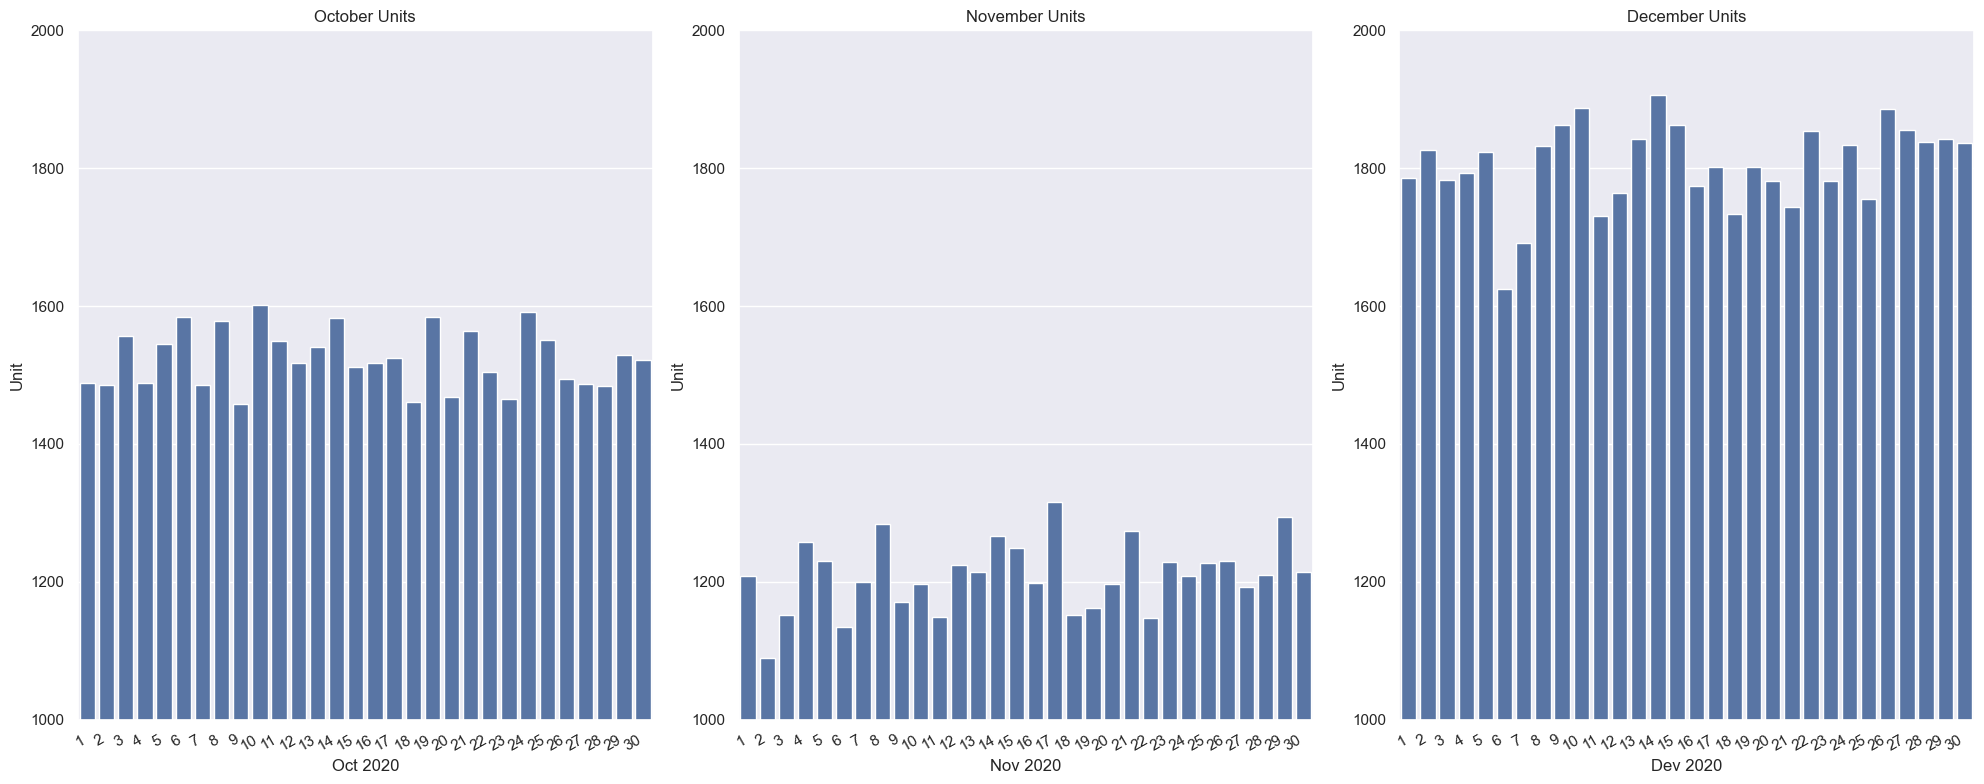

In [55]:
sns.set(rc={'figure.figsize':(20,8)})
fig, axes = plt.subplots(1, 3)
bp_oct = sns.barplot(x = df_oct.index, y='Unit', data=df_oct, ax=axes[0])
bp_nov = sns.barplot(x = df_nov.index, y='Unit', data=df_nov, ax=axes[1])
bp_dec = sns.barplot(x = df_dec.index, y='Unit', data=df_dec, ax=axes[2])
bp_oct.set(xlabel='Oct 2020', title='October Units')
bp_nov.set(xlabel='Nov 2020', title='November Units')
bp_dec.set(xlabel='Dev 2020', title='December Units')
bp_oct.set(ylim=(1000, 2000))
bp_nov.set(ylim=(1000, 2000))
bp_dec.set(ylim=(1000, 2000))
# to rotate labels 45 degrees and align the end of the text to the tick
o = bp_oct.set_xticklabels(oct_days, rotation=30, ha='right')
n = bp_nov.set_xticklabels(nov_days, rotation=30, ha='right')
d = bp_dec.set_xticklabels(dec_days, rotation=30, ha='right')
plt.tight_layout()

 - **Sales numbers for October, November and December**

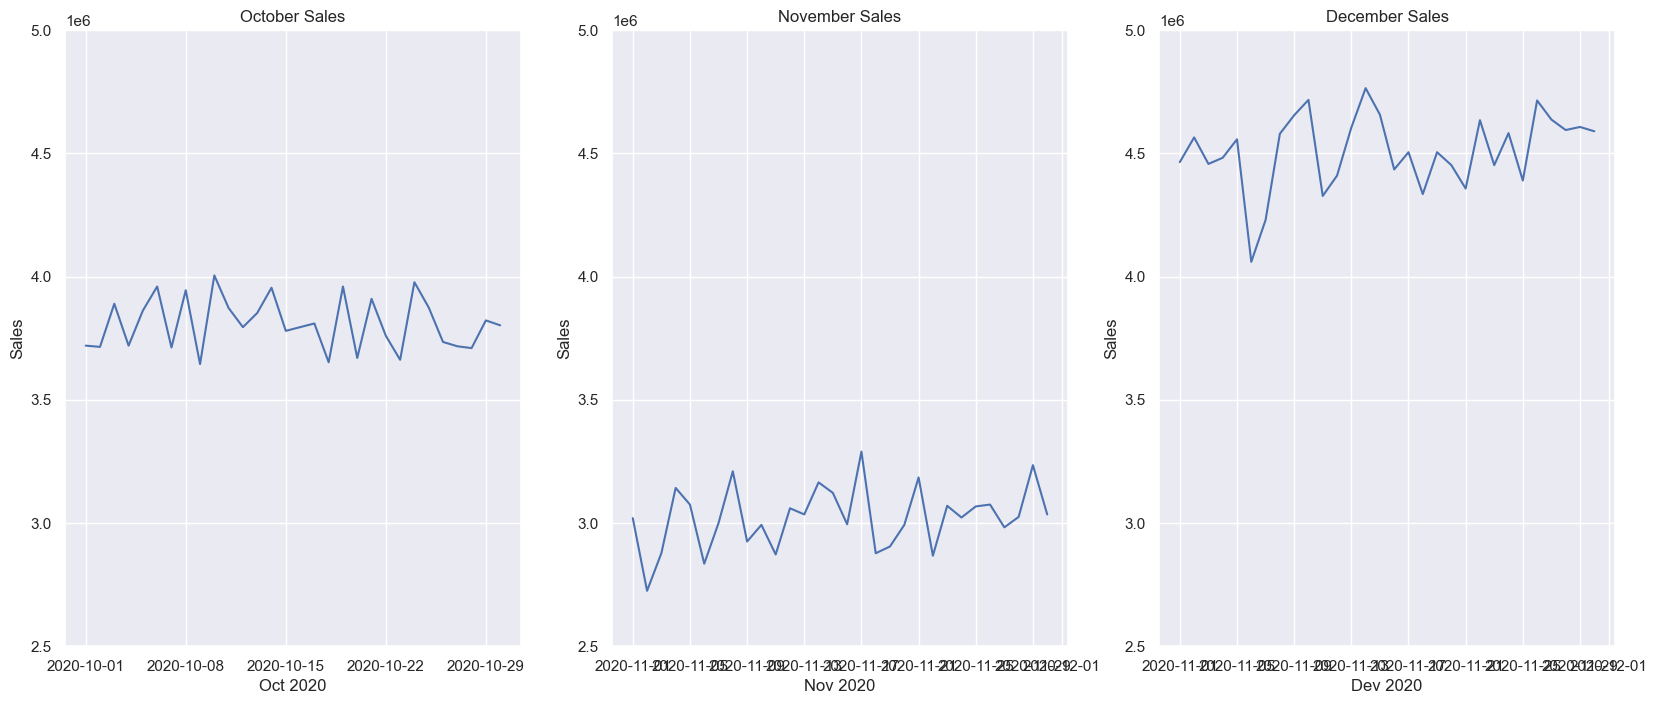

In [52]:
import matplotlib
sns.set(rc={'figure.figsize':(20,8)})
fig, axes = plt.subplots(1, 3)
lp_oct = sns.lineplot(x = df_oct.index, y = 'Sales', data=df_oct, ax=axes[0])
lp_nov = sns.lineplot(x = df_nov.index, y = 'Sales', data=df_nov, ax = axes[1])
lp_dec = sns.lineplot(x = df_nov.index, y = 'Sales', data=df_dec, ax = axes[2])
lp_oct.set(ylim=(2.5e6, 5.0e6))
lp_nov.set(ylim=(2.5e6, 5.0e6))
lp_dec.set(ylim=(2.5e6, 5.0e6))
lp_oct.set(xlabel='Oct 2020', title='October Sales')
lp_nov.set(xlabel='Nov 2020', title='November Sales')
lp_dec.set(xlabel='Dev 2020', title='December Sales')

loc = matplotlib.dates.DayLocator(bymonthday=range(1, 30, 7))

lp_oct.xaxis.set_major_locator(loc)

- **Consolidated 3 month Sales plot**

<Axes: xlabel='Date', ylabel='Sales'>

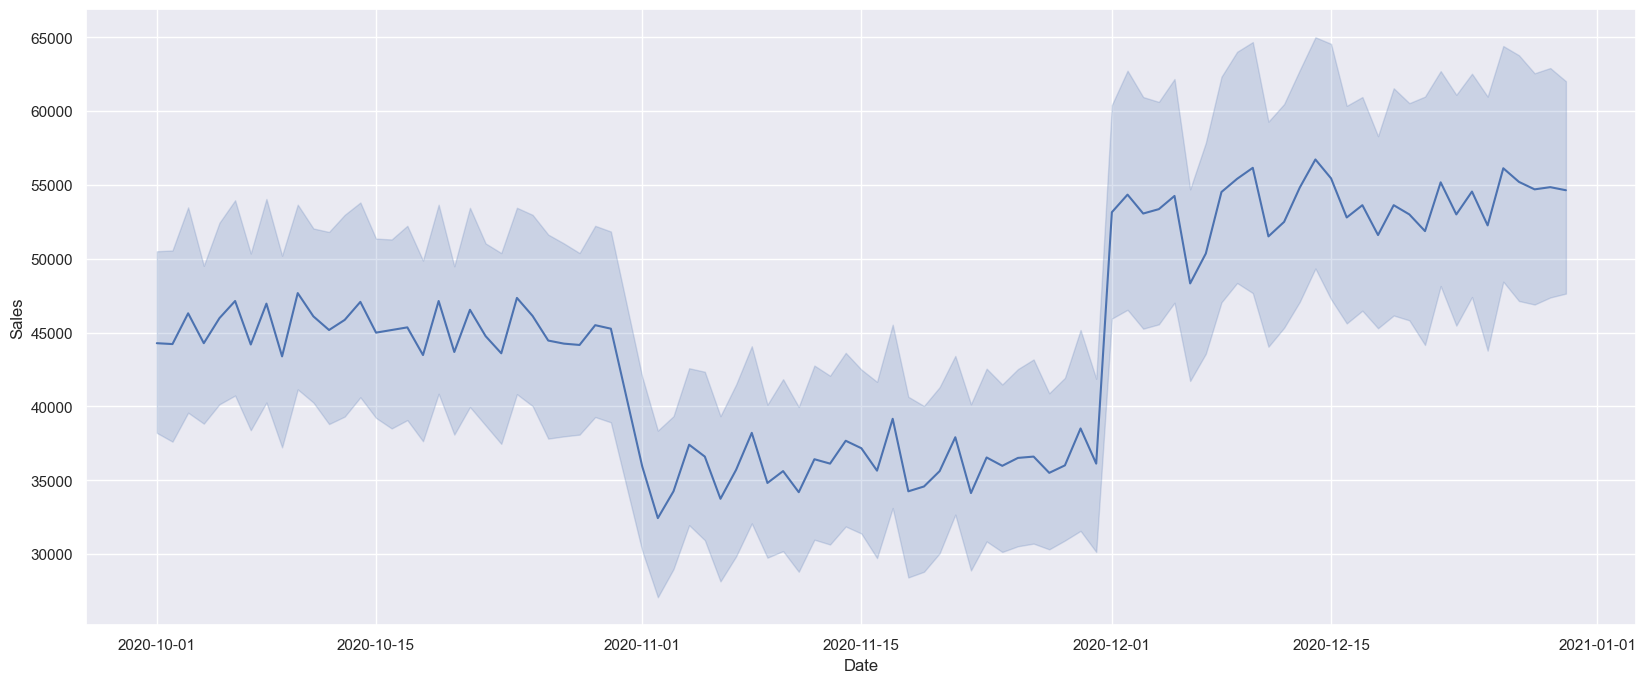

In [56]:
sns.set(rc={'figure.figsize':(20,8)})
sns.lineplot(x = 'Date', y = 'Sales', data = df)

#### Step 8: Obtain a Comprehensive Snapshot

C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_4752\3140143622.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  o = bp_oct.set_xticklabels(oct_days, rotation=30, ha='right')
C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_4752\3140143622.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  n = bp_nov.set_xticklabels(nov_days, rotation=30, ha='right')
C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_4752\3140143622.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  d = bp_dec.set_xticklabels(dec_days, rotation=30, ha='right')


[(2500000.0, 5000000.0)]

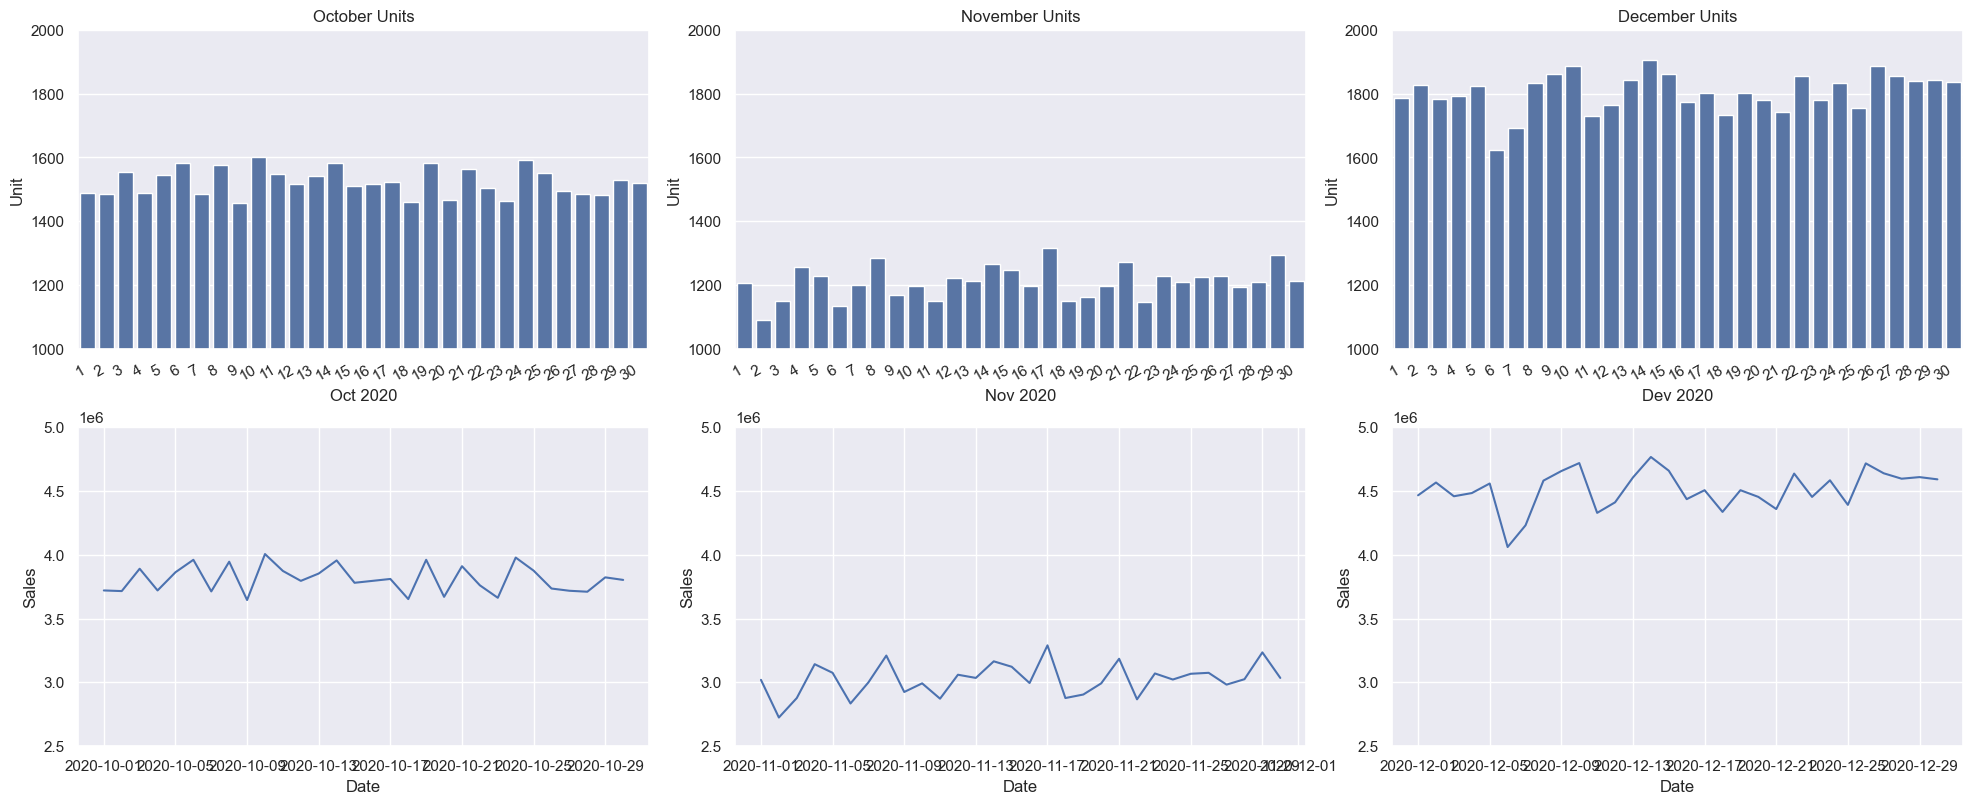

In [58]:
fig, axes = plt.subplots(2, 3)

bp_oct = sns.barplot(x = df_oct.index, y='Unit', data=df_oct, ax=axes[0,0])
bp_nov = sns.barplot(x = df_nov.index, y='Unit', data=df_nov, ax=axes[0,1])
bp_dec = sns.barplot(x = df_dec.index, y='Unit', data=df_dec, ax=axes[0,2])

bp_oct.set(xlabel='Oct 2020', title='October Units')
bp_nov.set(xlabel='Nov 2020', title='November Units')
bp_dec.set(xlabel='Dev 2020', title='December Units')

bp_oct.set(ylim=(1000, 2000))
bp_nov.set(ylim=(1000, 2000))
bp_dec.set(ylim=(1000, 2000))

o = bp_oct.set_xticklabels(oct_days, rotation=30, ha='right')
n = bp_nov.set_xticklabels(nov_days, rotation=30, ha='right')
d = bp_dec.set_xticklabels(dec_days, rotation=30, ha='right')
plt.tight_layout()

lp_oct = sns.lineplot(x = df_oct.index, y='Sales', data=df_oct, ax=axes[1,0])
lp_nov = sns.lineplot(x = df_nov.index, y='Sales', data=df_nov, ax=axes[1,1])
lp_dec = sns.lineplot(x = df_dec.index, y='Sales', data=df_dec, ax=axes[1,2])

lp_oct.set(ylim=(2.5e6, 5.0e6))
lp_nov.set(ylim=(2.5e6, 5.0e6))
lp_dec.set(ylim=(2.5e6, 5.0e6))

#### Step 9: Analyze Statewise Sales in the United States
Here we to pivot our main DataFrame ```df``` indexed on **State** and to get both sum and mean for **Units** and **Sales** 

In [65]:
state_pivot = pd.pivot_table(df, 
                             index='State', 
                             values=['Unit', 'Sales'], 
                             aggfunc=['sum', 'mean'])
state_pivot

sum                 mean           
           Sales   Unit         Sales       Unit
State                                           
 WA     22152500   8861  20511.574074   8.204630
AZ      22580000   9032  20907.407407   8.362963
CA      33417500  13367  30942.129630  12.376852
FL      58857500  23543  54497.685185  21.799074
KY     105565000  42226  97745.370370  39.098148
NY      74970000  29988  69416.666667  27.766667
TX      22760000   9104  21074.074074   8.429630

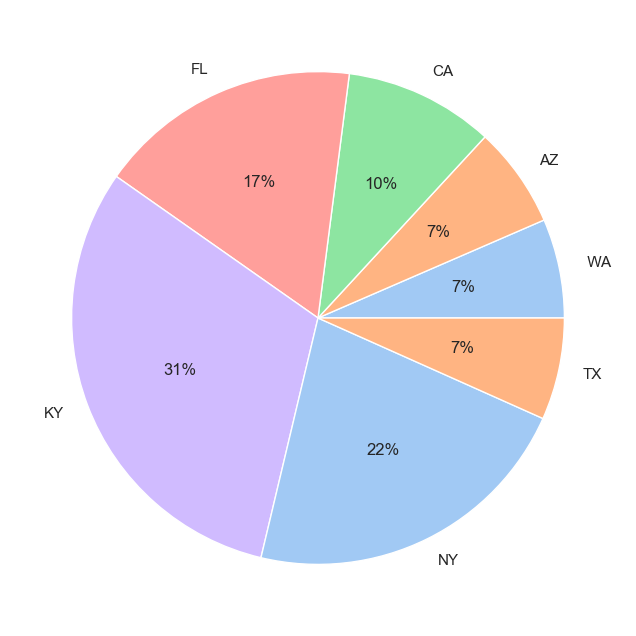

In [66]:
labels = state_pivot['mean']['Sales'].index.to_list()
# print(labels)
colors = sns.color_palette('pastel')[0:5]
plt.pie(state_pivot['mean']['Sales'], labels=labels, colors=colors, autopct='%.0f%%')
plt.show()

From the above pie chart, we can infer that more than 70% of the business come from the three states KY, NY and FL. Remaining states contribute just about 30% , which is based on the mean Sales data.

#### Step 10: Conduct Groupwise Analysis
Here we to pivot our main DataFrame ```df``` indexed on **Group** and to get both sum and mean for **Units** and **Sales** 

In [68]:
group_pivot = pd.pivot_table(df, index='Group', values=['Unit', 'Sales'], aggfunc=['sum', 'mean'])
group_pivot 

sum                 mean           
            Sales   Unit         Sales       Unit
Group                                            
Kids     85072500  34029  45011.904762  18.004762
Men      85750000  34300  45370.370370  18.148148
Seniors  84037500  33615  44464.285714  17.785714
Women    85442500  34177  45207.671958  18.083069

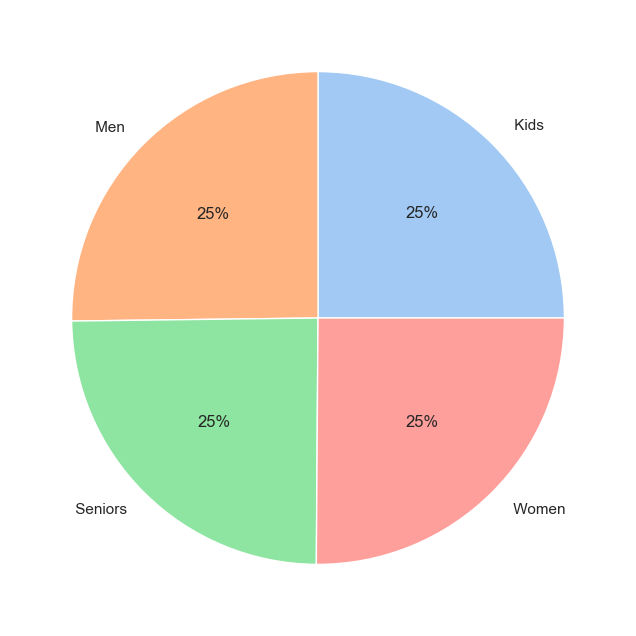

In [69]:
labels = group_pivot['mean']['Sales'].index.to_list()
# print(labels)
colors = sns.color_palette('pastel')[0:5]
plt.pie(group_pivot['mean']['Sales'], labels=labels, colors=colors, autopct='%.0f%%')
plt.show()

Here the group-wise distribution presents us an interesting picture. Men, Women, Kids and Seniors have equal share, in terms of the value of sales for the entire three-month period.

#### Step 11: Explore Timewise Analysis
Here we to pivot our main DataFrame ```df``` indexed on **TIme** and to get both sum and mean for **Units** and **Sales** 

In [70]:
time_pivot = pd.pivot_table(df, index='Time',values=['Unit', 'Sales'], aggfunc=['sum', 'mean'])
time_pivot

sum                 mean           
               Sales   Unit         Sales       Unit
Time                                                
Afternoon  114007500  45603  45241.071429  18.096429
Evening    112087500  44835  44479.166667  17.791667
Morning    114207500  45683  45320.436508  18.128175

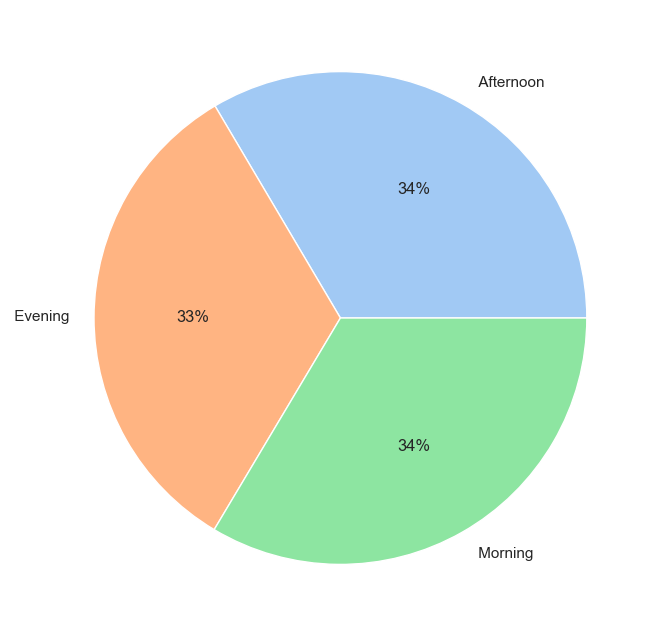

In [71]:
labels = time_pivot['mean']['Sales'].index.to_list()
# print(labels)
colors = sns.color_palette('pastel')[0:5]
plt.pie(time_pivot['mean']['Sales'], labels=labels, colors=colors, autopct='%.0f%%')
plt.show()

Here we can observe that time of sale doesn't matter for AAL as almost all the business are equi-distributed in terms of Morning, Afternoon or Evening Sales.

This report is based on the analysis of three month data - October, November and December 2020 for AAL, as the business was equally busy during all the times of store business hours.